# IceCube86 (`IceCube86-like_opticks.gdml`): geometry and hits per DOM

Companion notebook of `GDML/IceCube86-like_opticks.gdml` (made by `scripts/make_icecube_gdml.py` from LUCiD's
`IceCube86_full` configuration). Reads the geometry from the GDML file and the `OpticksHits` tree with
**uproot**; no ROOT or Geant4 needed.

| Function | What it does |
|---|---|
| `read_gdml_sensors(gdml)` | every DOM placement (`SensDet = PhotonDetector`): copy number and position |
| `assign_strings(sensors)` | groups DOMs into strings (same x, y), numbers DOMs top to bottom, flags DeepCore |
| `draw_string_map(sensors)` | top view of the strings (DeepCore highlighted) |
| `draw_string_profile(sensors)` | DOM depths on every string |
| `draw_doms_3d(sensors)` | 3D view of all DOMs and strings |
| `load_hits`, `match_hits`, `hits_per_sensor` | `OpticksHits` -> DataFrame -> DOM index (SensorID = copy number, checked against x,y,z) |
| `plot_string_dom_heatmap` | hits per DOM as a string x DOM grid |
| `plot_string_heatmap_top` | hits per string on the top view |
| `plot_event_display_3d` | IceCube-style display: marker size = hits, colour = first-hit time |


## Configuration
Use **absolute paths** (`~` and `$VARS` are expanded). Relative paths are resolved from the directory
Jupyter was started in.

In [37]:
from pathlib import Path

GDML_FILE = "/data/home/jupyter-ahiguera-mx/OpticalSims/GDML/IceCube86-like_opticks.gdml"
ROOT_FILE = "/data/home/jupyter-ahiguera-mx/opticks_test/test_icecube.root"   # gdml_det output
TREE_NAME = "OpticksHits"   # or "Geant4Hits"

EVENTS    = None            # None = all events, an int = one event, a list = several events
MATCH     = "id"            # "id": SensorID == copy number ; "position": nearest DOM to the hit x,y,z
LOG_COLOR = True
EVENT_DISPLAYS = 2          # how many single-event displays to draw
DEPTH_AXIS = "gdml"         # "gdml" (z in the GDML frame) or "lucid" (z_LUCiD = z_GDML + Z_OFFSET)
DEEPCORE_SPACING = 10.0     # m: strings whose DOMs are closer than this vertically are DeepCore

SAVE_DIR  = "/data/home/jupyter-ahiguera-mx/opticks_test/plots/icecube"            # absolute path to also save full-quality PNGs
INLINE_FORMAT = "jpeg"      # "jpeg" (small), "png" (sharper, ~5x bigger) or None (nothing inline; use SAVE_DIR)
INLINE_DPI    = 100          # resolution of the embedded figures (notebook size grows ~ DPI^2)

In [38]:
import os


def _find_by_name(name, roots, max_depth=5, limit=10):
    # Look for files called `name` under `roots` (bounded depth) to suggest the right path.
    hits = []
    for root in roots:
        root = Path(root)
        if not root.is_dir():
            continue
        base = len(root.parts)
        for dirpath, dirnames, filenames in os.walk(root):
            if len(Path(dirpath).parts) - base >= max_depth:
                dirnames[:] = []
            dirnames[:] = [d for d in dirnames if not d.startswith(".")]
            if name in filenames:
                hits.append(Path(dirpath) / name)
                if len(hits) >= limit:
                    return hits
    return hits


def absolute_path(p, what="file", must_exist=True):
    # Expand ~ / $VARS, require an absolute path, and (optionally) check that it exists.
    p = Path(os.path.expandvars(os.path.expanduser(str(p))))
    if not p.is_absolute():
        print(f"WARNING: {what} path {str(p)!r} is relative; resolving it from {Path.cwd()}")
        p = Path.cwd() / p
    p = p.resolve()
    if must_exist and not p.exists():
        found = list(dict.fromkeys(_find_by_name(p.name, [Path.home(), p.parent.parent])))  # de-duplicated
        hint = ("\n  files with that name:\n    " + "\n    ".join(map(str, found))) if found else \
               f"\n  no file called {p.name!r} found under {Path.home()}"
        raise FileNotFoundError(f"{what} not found: {p}{hint}")
    return p


GDML_FILE = absolute_path(GDML_FILE, "GDML file")
ROOT_FILE = absolute_path(ROOT_FILE, "ROOT file")
SAVE_DIR = absolute_path(SAVE_DIR, "SAVE_DIR", must_exist=False) if SAVE_DIR else None
print("GDML_FILE =", GDML_FILE)
print("ROOT_FILE =", ROOT_FILE)
if SAVE_DIR:
    print("SAVE_DIR  =", SAVE_DIR)

GDML_FILE = /data/home/jupyter-ahiguera-mx/OpticalSims/GDML/IceCube86-like_opticks.gdml
ROOT_FILE = /data/home/jupyter-ahiguera-mx/opticks_test/test_icecube.root
SAVE_DIR  = /data/home/jupyter-ahiguera-mx/opticks_test/plots/icecube


## Imports

In [39]:
import math
import re
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from scipy.spatial import cKDTree
import uproot
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats

plt.rcParams["figure.dpi"] = INLINE_DPI
if INLINE_FORMAT == "jpeg":
    set_matplotlib_formats("jpeg", pil_kwargs={"quality": 70, "optimize": True})
elif INLINE_FORMAT == "png":
    set_matplotlib_formats("png")
else:
    plt.ioff()
    set_matplotlib_formats("png")
print("uproot", uproot.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      f"| inline figures: {INLINE_FORMAT or 'off'} @ {INLINE_DPI} dpi")


def _save(fig, name):
    if SAVE_DIR:
        Path(SAVE_DIR).mkdir(parents=True, exist_ok=True)
        fig.savefig(Path(SAVE_DIR) / f"{name}.png", dpi=150, bbox_inches="tight")
    if not INLINE_FORMAT:
        plt.close(fig)

uproot 5.7.4 | numpy 2.4.3 | pandas 3.0.2 | inline figures: jpeg @ 100 dpi


## GDML reader
Same reader as `OpticksHits_heatmap.ipynb`: walks the volume tree with Geant4's placement convention and
returns one row per sensitive placement.

In [40]:
_UNITS = {"mm": 1.0, "cm": 10.0, "m": 1000.0, "km": 1e6, "um": 1e-3, "nm": 1e-6,
          "rad": 1.0, "mrad": 1e-3, "deg": math.pi / 180.0, "degree": math.pi / 180.0}
_ANG_DEFAULT, _LEN_DEFAULT = "rad", "mm"     # GDML defaults


class _Expr:
    # Evaluates GDML numeric attributes ("16900", "2*R", "180*deg", "pi/2") with <define> constants.
    def __init__(self):
        self.ns = {"pi": math.pi, "e": math.e, "sqrt": math.sqrt, "sin": math.sin, "cos": math.cos,
                   "tan": math.tan, "asin": math.asin, "acos": math.acos, "atan": math.atan,
                   "atan2": math.atan2, "exp": math.exp, "log": math.log, "abs": abs, "pow": pow}
        self.ns.update(_UNITS)

    def __call__(self, s, default=0.0):
        if s is None:
            return default
        try:
            return float(s)
        except ValueError:
            return float(eval(str(s).replace("^", "**"), {"__builtins__": {}}, self.ns))

    def define(self, name, value):
        self.ns[name] = self(value)


def _rot_matrix(ax, ay, az):
    # CLHEP: rot.rotateX(ax); rot.rotateY(ay); rot.rotateZ(az)  ->  M = Rz @ Ry @ Rx
    cx, sx, cy, sy, cz, sz = math.cos(ax), math.sin(ax), math.cos(ay), math.sin(ay), math.cos(az), math.sin(az)
    Rx = np.array([[1, 0, 0], [0, cx, -sx], [0, sx, cx]])
    Ry = np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]])
    Rz = np.array([[cz, -sz, 0], [sz, cz, 0], [0, 0, 1]])
    return Rz @ Ry @ Rx


def read_gdml_sensors(gdml_path, sensor_aux=("SensDet", "PD"), sensor_value="PhotonDetector",
                      sensor_lvs=None, verbose=True):
    # Return a DataFrame with one row per sensitive placement:
    #   copynumber, lv, pv, x, y, z [mm, sensor-volume origin], dir_x/y/z (sensor local +x in global frame),
    #   depth, surface ('barrel' / 'top' / 'bottom', for cylinder-like detectors)
    # Sensors = LVs carrying <auxiliary auxtype in sensor_aux auxvalue=sensor_value/> (as OpticalSims'
    # DetectorConstruction does), or the explicit list `sensor_lvs`.
    root = ET.parse(str(gdml_path)).getroot()
    for el in root.iter():                          # drop any XML namespace prefixes
        if isinstance(el.tag, str) and "}" in el.tag:
            el.tag = el.tag.split("}", 1)[1]
    ev = _Expr()

    positions, rotations = {}, {}
    for d in root.findall("define"):
        for el in d:
            name = el.get("name")
            if el.tag in ("constant", "variable"):
                ev.define(name, el.get("value"))
            elif el.tag == "quantity":
                ev.define(name, f"({el.get('value')})*{el.get('unit', '1')}")
    for d in root.findall("define"):
        for el in d:
            if el.tag == "position":
                positions[el.get("name")] = el
            elif el.tag == "rotation":
                rotations[el.get("name")] = el

    def vec(el, kind):
        if el is None:
            return np.zeros(3)
        u = _UNITS.get(el.get("unit", _LEN_DEFAULT if kind == "pos" else _ANG_DEFAULT), 1.0)
        return np.array([ev(el.get(k), 0.0) for k in "xyz"]) * u

    structure = root.find("structure")
    volumes = {v.get("name"): v for v in structure if v.tag in ("volume", "assembly")}

    sensors = set(sensor_lvs or [])
    if not sensor_lvs:
        for name, v in volumes.items():
            for aux in v.findall("auxiliary"):
                if aux.get("auxtype") in sensor_aux and aux.get("auxvalue") == sensor_value:
                    sensors.add(name)
    if not sensors:
        raise RuntimeError("no sensitive volumes found (no SensDet/PD = PhotonDetector auxiliary)")

    world = root.find("setup/world").get("ref")
    rows, stack = [], [(world, np.zeros(3), np.eye(3), 0)]
    while stack:
        lv, t, R, depth = stack.pop()
        for pv in volumes[lv].findall("physvol"):
            ref = pv.find("volumeref")
            if ref is None:
                raise NotImplementedError("physvol without volumeref (inline <file>) is not supported")
            child = ref.get("ref")
            pos = pv.find("position")
            if pos is None and pv.find("positionref") is not None:
                pos = positions[pv.find("positionref").get("ref")]
            rot = pv.find("rotation")
            if rot is None and pv.find("rotationref") is not None:
                rot = rotations[pv.find("rotationref").get("ref")]
            Rloc = _rot_matrix(*vec(rot, "rot")).T          # GDML -> Geant4 uses the inverse
            tg, Rg = t + R @ vec(pos, "pos"), R @ Rloc
            if child in sensors:
                d = Rg[:, 0]
                rows.append((int(pv.get("copynumber", 0)), child, pv.get("name", child + "_PV"),
                             *tg, *d, depth + 1))
            elif child in volumes:
                stack.append((child, tg, Rg, depth + 1))

    df = pd.DataFrame(rows, columns=["copynumber", "lv", "pv", "x", "y", "z",
                                     "dir_x", "dir_y", "dir_z", "depth"])
    df = df.sort_values("copynumber", kind="stable").reset_index(drop=True)

    # cylinder bookkeeping: caps are the sensors sitting at the extreme z planes
    tol = 1.0  # mm
    zmax, zmin = df.z.max(), df.z.min()
    df["surface"] = np.where(df.z > zmax - tol, "top", np.where(df.z < zmin + tol, "bottom", "barrel"))
    df.attrs["sensor_radius"] = _sensor_radius(root, volumes, sorted(sensors), ev)
    df.attrs["gdml"] = str(gdml_path)

    if verbose:
        print(f"{gdml_path}: {len(df)} sensors in LVs {sorted(sensors)}")
        print(df.groupby(["lv", "surface"]).size().rename("n").to_string())
        dup = df.copynumber.duplicated().sum()
        if dup:
            print(f"WARNING: {dup} duplicated copy numbers -> SensorID is not unique per sensor")
        print(f"sensor radius ~ {df.attrs['sensor_radius']} mm")
    return df


def _sensor_radius(root, volumes, sensor_lvs, ev):
    # Radius of the first <orb>/<sphere> found in a sensor LV's solid tree (None if there is none).
    solids = {s.get("name"): s for s in root.find("solids")}
    for lv in sensor_lvs:
        todo = [volumes[lv].find("solidref").get("ref")]
        while todo:
            s = solids.get(todo.pop())
            if s is None:
                continue
            u = _UNITS.get(s.get("lunit", "mm"), 1.0)
            if s.tag == "orb":
                return ev(s.get("r")) * u
            if s.tag == "sphere":
                return ev(s.get("rmax")) * u
            todo += [c.get("ref") for c in s if c.tag in ("first", "second")]
    return None

## Strings, DOM numbering and the ice envelope

In [41]:
def read_envelope(gdml_path):
    # Ice envelope radius / half-height (mm) and the LUCiD z offset written in the GDML header.
    text = Path(gdml_path).read_text()
    m = re.search(r'<tube name="IceEnvelope"[^>]*rmax="([\d.eE+-]+)"[^>]*z="([\d.eE+-]+)"', text)
    R, H = (float(m.group(1)), float(m.group(2))) if m else (None, None)
    z = re.search(r"z_GDML = z_LUCiD - \(([-\d.eE+]+) mm\)", text)
    zoff = float(z.group(1)) if z else 0.0
    print(f"ice envelope: R = {R / 1e3 if R else float('nan'):.0f} m, height = {H / 1e3 if H else float('nan'):.0f} m; "
          f"z_LUCiD = z_GDML + ({zoff / 1e3:.1f} m)")
    return dict(R=R, H=H, zoff=zoff)


def assign_strings(sensors, xy_tol=1000.0, deepcore_spacing=DEEPCORE_SPACING):
    # string = DOMs sharing (x, y) within xy_tol mm, numbered by their lowest copy number;
    # dom = 0 at the top of each string; deepcore = median vertical DOM spacing < deepcore_spacing m.
    xy = sensors[["x", "y"]].to_numpy()
    key = np.round(xy / xy_tol).astype(int)
    _, sid = np.unique(key, axis=0, return_inverse=True)
    first = pd.Series(sensors.copynumber.to_numpy()).groupby(sid.ravel()).min()
    order = {old: new for new, old in enumerate(first.sort_values().index)}
    sensors["string"] = [order[s] for s in sid.ravel()]
    sensors["dom"] = sensors.groupby("string").z.rank(ascending=False, method="first").astype(int) - 1
    spacing = sensors.groupby("string").z.apply(lambda z: np.median(np.abs(np.diff(np.sort(z.to_numpy())))) / 1e3)
    sensors["deepcore"] = sensors.string.map(spacing < deepcore_spacing)
    print(f"{sensors.string.nunique()} strings ({sensors.groupby('string').deepcore.first().sum()} DeepCore), "
          f"{sensors.groupby('string').size().max()} DOMs per string max")
    return sensors


def depth(z_mm):
    # z in metres on the axis chosen by DEPTH_AXIS.
    return (np.asarray(z_mm) + (ENVELOPE["zoff"] if DEPTH_AXIS == "lucid" else 0.0)) / 1e3


def zlabel():
    return "z$_{LUCiD}$ [m]" if DEPTH_AXIS == "lucid" else "z [m] (GDML frame)"


def string_table(sensors):
    return sensors.groupby("string").agg(x=("x", "first"), y=("y", "first"), deepcore=("deepcore", "first"),
                                         ndom=("dom", "size"), zmin=("z", "min"), zmax=("z", "max"))

## Geometry plots

In [42]:
def draw_string_map(sensors, label=True):
    st = string_table(sensors)
    fig, ax = plt.subplots(figsize=(9, 8))
    if ENVELOPE["R"]:
        t = np.linspace(0, 2 * np.pi, 200)
        ax.plot(ENVELOPE["R"] / 1e3 * np.cos(t), ENVELOPE["R"] / 1e3 * np.sin(t), color="0.6", lw=0.8,
                label=f"ice envelope (R = {ENVELOPE['R'] / 1e3:.0f} m)")
    for dc, c, lab in ((False, "C0", "IceCube strings"), (True, "C3", "DeepCore strings")):
        g = st[st.deepcore == dc]
        ax.scatter(g.x / 1e3, g.y / 1e3, s=40 if not dc else 25, color=c, label=f"{lab} ({len(g)})", zorder=3)
    if label:
        for s, r in st.iterrows():
            ax.annotate(str(s), (r.x / 1e3, r.y / 1e3), xytext=(3, 3), textcoords="offset points", fontsize=6)
    ax.set_aspect("equal")
    ax.set(xlabel="x [m]", ylabel="y [m]", title=f"{len(st)} strings, {len(sensors)} DOMs (top view)")
    ax.legend(loc="lower left", fontsize=8)
    fig.tight_layout()
    _save(fig, "string_map")
    return fig


def draw_string_profile(sensors):
    fig, ax = plt.subplots(figsize=(14, 5))
    c = np.where(sensors.deepcore, "C3", "C0")
    ax.scatter(sensors.string, depth(sensors.z), s=3, c=c)
    if ENVELOPE["H"]:
        for zz in (-ENVELOPE["H"] / 2, ENVELOPE["H"] / 2):
            ax.axhline(depth(zz), color="0.6", lw=0.8)
    ax.set(xlabel="string", ylabel=zlabel(), title="DOM depth per string (blue IceCube, red DeepCore; lines: ice envelope)")
    fig.tight_layout()
    _save(fig, "string_profile")
    return fig


def draw_doms_3d(sensors, elev=15, azim=-60):
    st = string_table(sensors)
    fig = plt.figure(figsize=(10, 9))
    ax = fig.add_subplot(projection="3d")
    for s, r in st.iterrows():
        ax.plot([r.x / 1e3] * 2, [r.y / 1e3] * 2, [depth(r.zmin), depth(r.zmax)], color="0.7", lw=0.4)
    ax.scatter(sensors.x / 1e3, sensors.y / 1e3, depth(sensors.z), s=1.5,
               c=np.where(sensors.deepcore, "C3", "C0"), depthshade=False)
    ax.set(xlabel="x [m]", ylabel="y [m]", zlabel=zlabel(), title=f"{len(sensors)} DOMs")
    ext = np.array([np.ptp(sensors.x), np.ptp(sensors.y), np.ptp(sensors.z)])
    ax.set_box_aspect(ext / ext.max())
    ax.view_init(elev=elev, azim=azim)
    _save(fig, "doms_3d")
    return fig

## Hits

In [43]:
HIT_BRANCHES = ["evtID", "hit_Id", "SensorID", "x", "y", "z", "t", "wavelength", "boundary"]


def load_hits(root_file, tree=TREE_NAME, events=None):
    with uproot.open(root_file) as f:
        if tree not in f:
            raise KeyError(f"{tree!r} not in {root_file}; keys: {f.keys()}")
        t = f[tree]
        df = t.arrays([b for b in HIT_BRANCHES if b in t.keys()], library="pd")
    if events is not None:
        ev = [events] if np.isscalar(events) else list(events)
        df = df[df.evtID.isin(ev)]
    df = df.reset_index(drop=True)
    print(f"{Path(root_file).name}:{tree}: {len(df):,} hits in {df.evtID.nunique()} event(s)")
    return df


def match_hits(hits, sensors, how=MATCH):
    # Adds 'dom_row' (row in `sensors`, -1 = unknown) and 'dom_dist' (hit to DOM centre, mm).
    tree = cKDTree(sensors[["x", "y", "z"]].to_numpy())
    dist, near = tree.query(hits[["x", "y", "z"]].to_numpy(float))
    if how == "id":
        lut = pd.Series(np.arange(len(sensors)), index=sensors.copynumber.to_numpy())
        hits["dom_row"] = hits.SensorID.map(lut).fillna(-1).astype(int)
        agree = (hits.dom_row.to_numpy() == near).mean()
        print(f"SensorID -> DOM: {(hits.dom_row < 0).sum()} unknown ids; nearest DOM agrees for {agree:.2%} of hits")
    else:
        hits["dom_row"] = near
    ok = hits.dom_row.to_numpy() >= 0
    p = sensors[["x", "y", "z"]].to_numpy()[np.where(ok, hits.dom_row, 0)]
    hits["dom_dist"] = np.where(ok, np.linalg.norm(hits[["x", "y", "z"]].to_numpy(float) - p, axis=1), np.nan)
    return hits


def hits_per_sensor(hits, sensors):
    sel = hits.dom_row >= 0
    return np.bincount(hits.dom_row[sel], minlength=len(sensors)).astype(float)


def first_hit_time(hits, sensors):
    t = np.full(len(sensors), np.nan)
    g = hits[hits.dom_row >= 0].groupby("dom_row").t.min()
    t[g.index.to_numpy()] = g.to_numpy()
    return t

## Heat maps and checks

In [44]:
def _norm(counts, log):
    # Log colour scale for wide ranges; linear (integer-friendly) when the counts span < 20x.
    hit = counts > 0
    vmax = counts.max() if hit.any() else 1
    vmin = counts[hit].min() if hit.any() else 1
    if log and vmax / max(vmin, 1e-9) >= 20:
        return LogNorm(vmin=max(vmin, 1e-3), vmax=vmax)
    return Normalize(vmin=min(vmin, 1) if hit.any() else 0, vmax=max(vmax, 1))


def plot_string_dom_heatmap(sensors, counts, log=LOG_COLOR, cmap="viridis", title="hits per DOM",
                            save_as="heatmap_string_dom"):
    # Grid: x = string, y = DOM number (0 = top); grey = DOM without hits, white = no DOM.
    counts = np.asarray(counts, float)
    ns, nd = sensors.string.max() + 1, sensors.dom.max() + 1
    grid = np.full((nd, ns), np.nan)
    grid[sensors.dom.to_numpy(), sensors.string.to_numpy()] = counts
    fig, ax = plt.subplots(figsize=(15, 6))
    empty = np.where(grid == 0, 1.0, np.nan)
    ax.imshow(empty, aspect="auto", cmap="Greys", vmin=0, vmax=4, origin="upper", interpolation="nearest")
    lit = np.where(grid > 0, grid, np.nan)
    im = ax.imshow(lit, aspect="auto", cmap=cmap, norm=_norm(counts, log), origin="upper", interpolation="nearest")
    dc = sorted(sensors.loc[sensors.deepcore, "string"].unique())
    if dc:
        ax.axvspan(min(dc) - 0.5, max(dc) + 0.5, color="C3", alpha=0.06, lw=0)
        ax.text((min(dc) + max(dc)) / 2, -1.5, "DeepCore", ha="center", fontsize=8, color="C3")
    fig.colorbar(im, ax=ax, pad=0.01, label="hits")
    ax.set(xlabel="string", ylabel="DOM (0 = top of string)",
           title=f"{title}: {counts.sum():,.0f} hits on {(counts > 0).sum()}/{len(counts)} DOMs")
    fig.tight_layout()
    _save(fig, save_as)
    return fig


def plot_string_heatmap_top(sensors, counts, log=LOG_COLOR, cmap="viridis", title="hits per string",
                            save_as="heatmap_strings_top"):
    counts = np.asarray(counts, float)
    st = string_table(sensors)
    per = pd.Series(counts).groupby(sensors.string.to_numpy()).sum().reindex(st.index).to_numpy()
    fig, ax = plt.subplots(figsize=(9, 8))
    if ENVELOPE["R"]:
        t = np.linspace(0, 2 * np.pi, 200)
        ax.plot(ENVELOPE["R"] / 1e3 * np.cos(t), ENVELOPE["R"] / 1e3 * np.sin(t), color="0.6", lw=0.8)
    hit = per > 0
    ax.scatter(st.x[~hit] / 1e3, st.y[~hit] / 1e3, s=25, color="0.85", edgecolor="0.6", lw=0.4)
    sc = ax.scatter(st.x[hit] / 1e3, st.y[hit] / 1e3, s=25 + 300 * np.sqrt(per[hit] / per.max()),
                    c=per[hit], cmap=cmap, norm=_norm(per, log), edgecolor="k", lw=0.3, zorder=3)
    fig.colorbar(sc, ax=ax, shrink=0.8, label="hits per string")
    ax.set_aspect("equal")
    ax.set(xlabel="x [m]", ylabel="y [m]", title=f"{title}: {hit.sum()}/{len(per)} strings hit")
    fig.tight_layout()
    _save(fig, save_as)
    return fig


def plot_event_display_3d(sensors, counts, t_first=None, elev=15, azim=-60, cmap="rainbow_r",
                          title="event display", save_as="event_display_3d"):
    # IceCube-style: hit DOMs as spheres with size ~ hits, colour = first-hit time (red = early).
    counts = np.asarray(counts, float)
    hit = counts > 0
    fig = plt.figure(figsize=(11, 9))
    ax = fig.add_subplot(projection="3d")
    st = string_table(sensors)
    for s, r in st.iterrows():
        ax.plot([r.x / 1e3] * 2, [r.y / 1e3] * 2, [depth(r.zmin), depth(r.zmax)], color="0.85", lw=0.4)
    ax.scatter(sensors.x[~hit] / 1e3, sensors.y[~hit] / 1e3, depth(sensors.z[~hit]), s=0.3, color="0.75",
               depthshade=False)
    size = 4 + 120 * np.sqrt(counts[hit] / counts.max()) if hit.any() else []
    col = t_first[hit] if t_first is not None else counts[hit]
    sc = ax.scatter(sensors.x[hit] / 1e3, sensors.y[hit] / 1e3, depth(sensors.z[hit]), s=size, c=col,
                    cmap=cmap if t_first is not None else "viridis", depthshade=False, edgecolor="k", lw=0.2)
    if hit.any():
        fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.1, label="first-hit time [ns]" if t_first is not None else "hits")
    ext = np.array([np.ptp(sensors.x), np.ptp(sensors.y), np.ptp(sensors.z)])
    ax.set_box_aspect(ext / ext.max())
    ax.set(xlabel="x [m]", ylabel="y [m]", zlabel=zlabel(),
           title=f"{title}: {counts.sum():,.0f} hits on {hit.sum()} DOMs (size = hits)")
    ax.view_init(elev=elev, azim=azim)
    _save(fig, save_as)
    return fig


def plot_hit_checks(hits, sensors, bins=100, save_as="hit_checks"):
    fig, axs = plt.subplots(2, 3, figsize=(16, 8))
    axs = axs.ravel()
    nh = hits.groupby("evtID").size()
    axs[0].hist(nh, bins=min(50, max(5, len(nh))))
    axs[0].set(xlabel="hits per event", ylabel="events", title=f"Nhits: mean {nh.mean():,.0f}")
    axs[1].hist(hits.t, bins=bins, range=(hits.t.min(), np.percentile(hits.t, 99.5)))
    axs[1].set(xlabel="t [ns]", ylabel="hits", yscale="log", title="hit time")
    if "wavelength" in hits:
        axs[2].hist(hits.wavelength, bins=bins)
        axs[2].set(xlabel="wavelength [nm]", ylabel="hits", title="hit wavelength")
    rs = sensors.attrs.get("sensor_radius") or 165.0
    axs[3].hist(hits.dom_dist, bins=bins, range=(0, 1.5 * rs))
    axs[3].axvline(rs, color="C3", ls="--", label="DOM radius")
    axs[3].set(xlabel="|hit - DOM centre| [mm]", ylabel="hits", title="hit on its DOM sphere")
    axs[3].legend()
    ok = hits.dom_row >= 0
    axs[4].hist(depth(sensors.z.to_numpy()[hits.dom_row[ok]]), bins=60, orientation="horizontal")
    axs[4].set(ylabel=zlabel(), xlabel="hits", title="hits vs depth")
    nds = pd.Series(1, index=hits.dom_row[ok]).groupby(level=0).size()
    axs[5].hist(nds, bins=np.arange(1, max(nds.max(), 2) + 2) - 0.5 if nds.max() < 60 else 60)
    axs[5].set(xlabel="hits per hit DOM", ylabel="DOMs", yscale="log", title="DOM occupancy")
    fig.tight_layout()
    _save(fig, save_as)
    return fig

## 1. Geometry

In [45]:
ENVELOPE = read_envelope(GDML_FILE)
sensors = assign_strings(read_gdml_sensors(GDML_FILE, verbose=False).drop(columns="surface"))
print(f"{GDML_FILE.name}: {len(sensors)} DOMs, copy numbers {sensors.copynumber.min()}..{sensors.copynumber.max()} "
      f"(unique: {sensors.copynumber.is_unique}), DOM radius {sensors.attrs.get('sensor_radius')} mm")
sensors.head()

ice envelope: R = 675 m, height = 1103 m; z_LUCiD = z_GDML + (-1951.5 m)
86 strings (8 DeepCore), 60 DOMs per string max
IceCube86-like_opticks.gdml: 5160 DOMs, copy numbers 0..5159 (unique: True), DOM radius 165.0 mm


,copynumber,lv,pv,x,y,z,dir_x,dir_y,dir_z,depth,string,dom,deepcore
0,0,volDOM,volDOM_PV,0.0,0.0,-501500.0,1.0,0.0,0.0,2,0,59,False
1,1,volDOM,volDOM_PV,0.0,0.0,-484500.0,1.0,0.0,0.0,2,0,58,False
2,2,volDOM,volDOM_PV,0.0,0.0,-467500.0,1.0,0.0,0.0,2,0,57,False
3,3,volDOM,volDOM_PV,0.0,0.0,-450500.0,1.0,0.0,0.0,2,0,56,False
4,4,volDOM,volDOM_PV,0.0,0.0,-433500.0,1.0,0.0,0.0,2,0,55,False


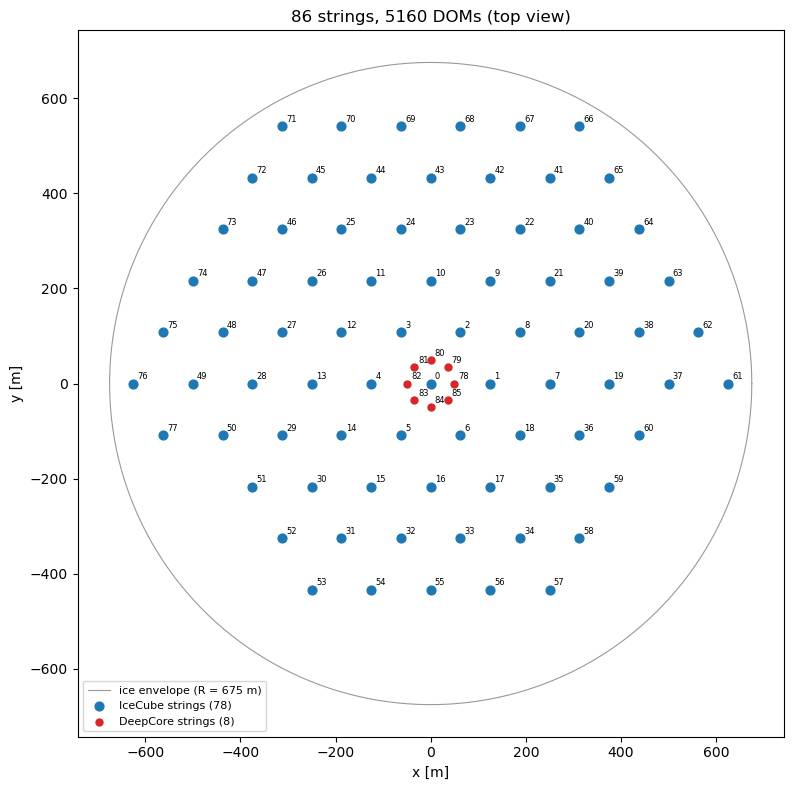

In [46]:
draw_string_map(sensors);

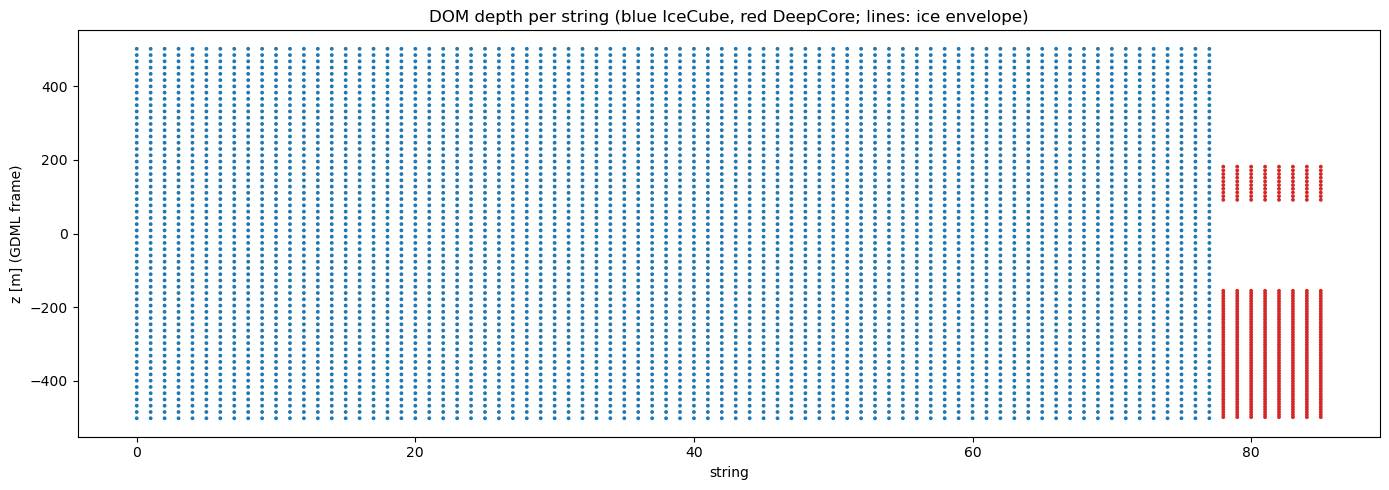

In [47]:
draw_string_profile(sensors);

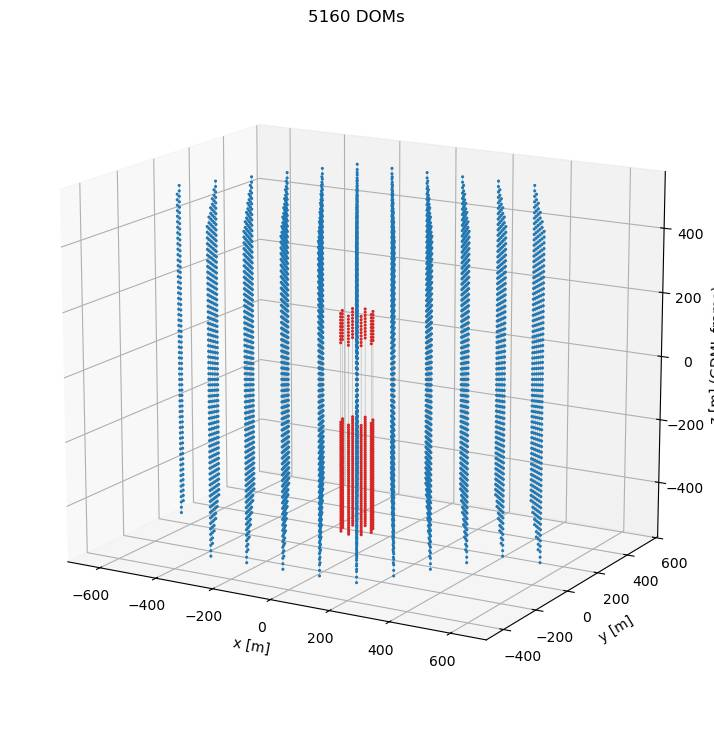

In [48]:
draw_doms_3d(sensors);

## 2. Hits

In [49]:
hits = load_hits(ROOT_FILE, events=EVENTS)
hits = match_hits(hits, sensors, how=MATCH)
counts = hits_per_sensor(hits, sensors)
hits.head()

test_icecube.root:OpticksHits: 1,752 hits in 10 event(s)
SensorID -> DOM: 0 unknown ids; nearest DOM agrees for 100.00% of hits


,evtID,hit_Id,SensorID,x,y,z,t,wavelength,boundary,dom_row,dom_dist
0,0,228219,4736,49887.917969,-36.609215,151614.781250,763.798279,339.305756,2,4736,164.551973
1,0,297169,4799,35511.031250,35409.414062,181492.187500,375.653534,377.673431,2,4799,165.000680
2,0,405278,4798,35242.441406,35243.500000,171455.593750,223.210785,318.525208,2,4798,165.002253
3,0,435942,4739,49958.015625,-78.464249,181638.953125,268.787659,326.714264,2,4739,165.006960
4,0,506913,4734,50109.582031,121.555870,131521.000000,715.437073,406.547058,2,4734,165.000155


## 3. Heat maps - all selected events

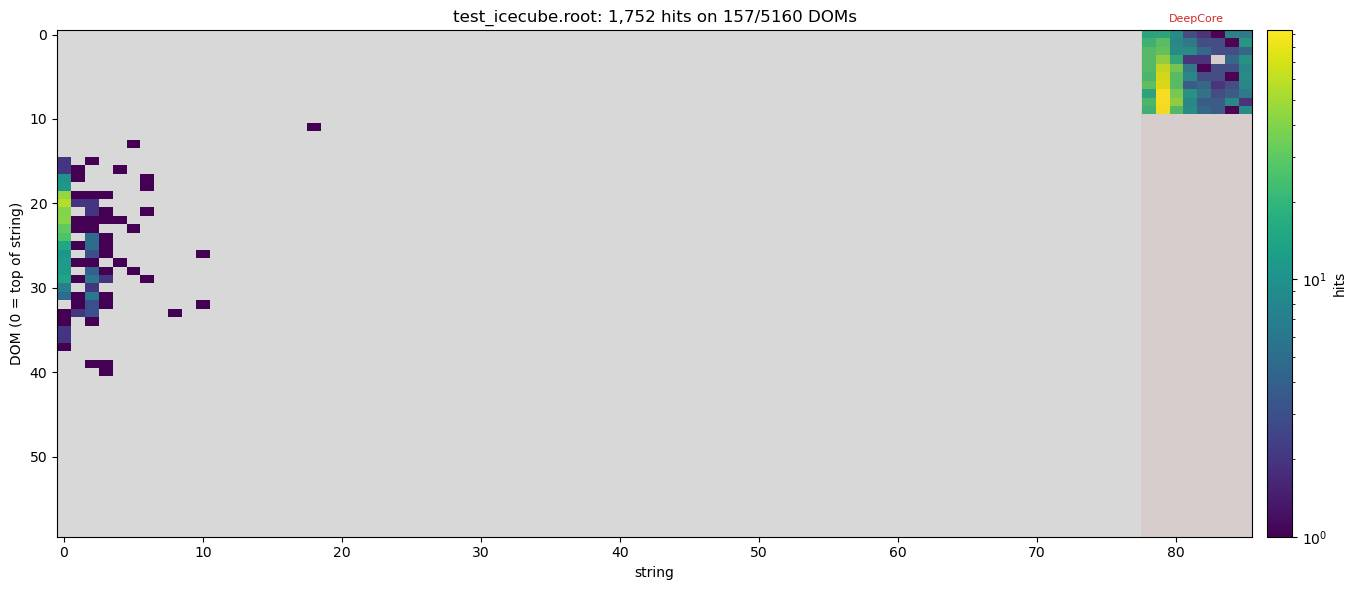

In [50]:
plot_string_dom_heatmap(sensors, counts, title=ROOT_FILE.name);

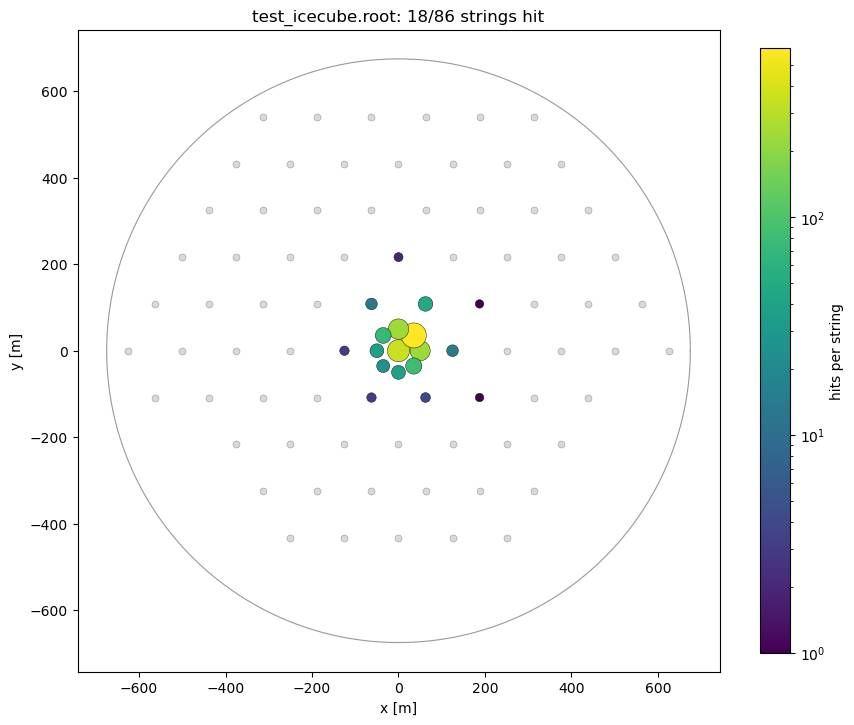

In [51]:
plot_string_heatmap_top(sensors, counts, title=ROOT_FILE.name);

## 4. Event displays

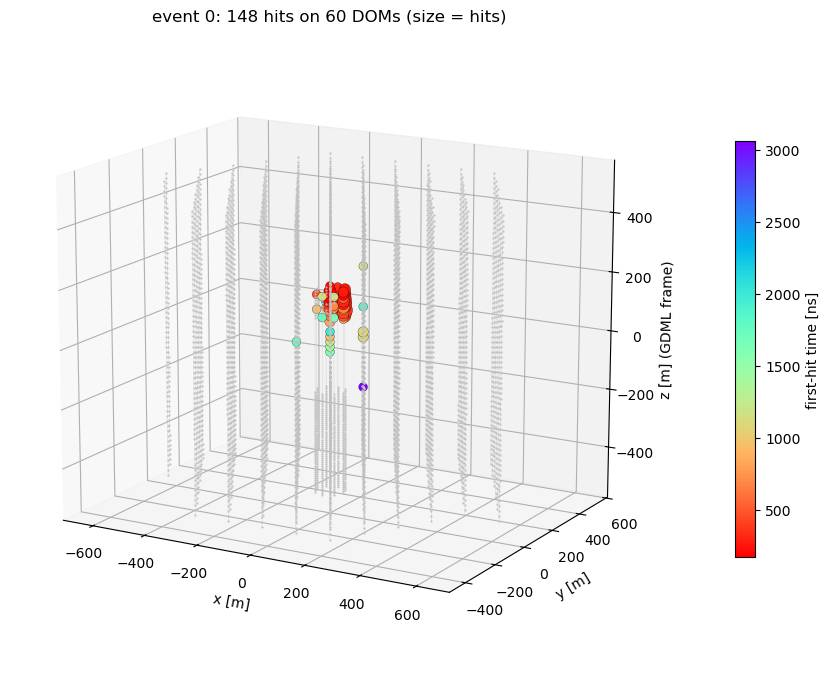

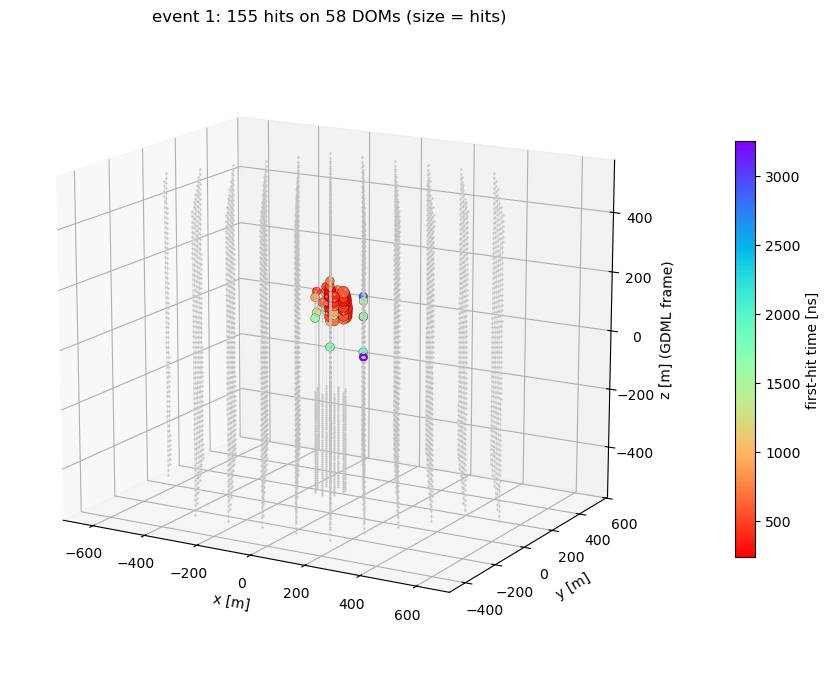

In [52]:
for evt in sorted(hits.evtID.unique())[:EVENT_DISPLAYS]:
    h = hits[hits.evtID == evt]
    plot_event_display_3d(sensors, hits_per_sensor(h, sensors), first_hit_time(h, sensors),
                          title=f"event {evt}", save_as=f"event_display_evt{evt}")

## 5. Checks and the busiest DOMs

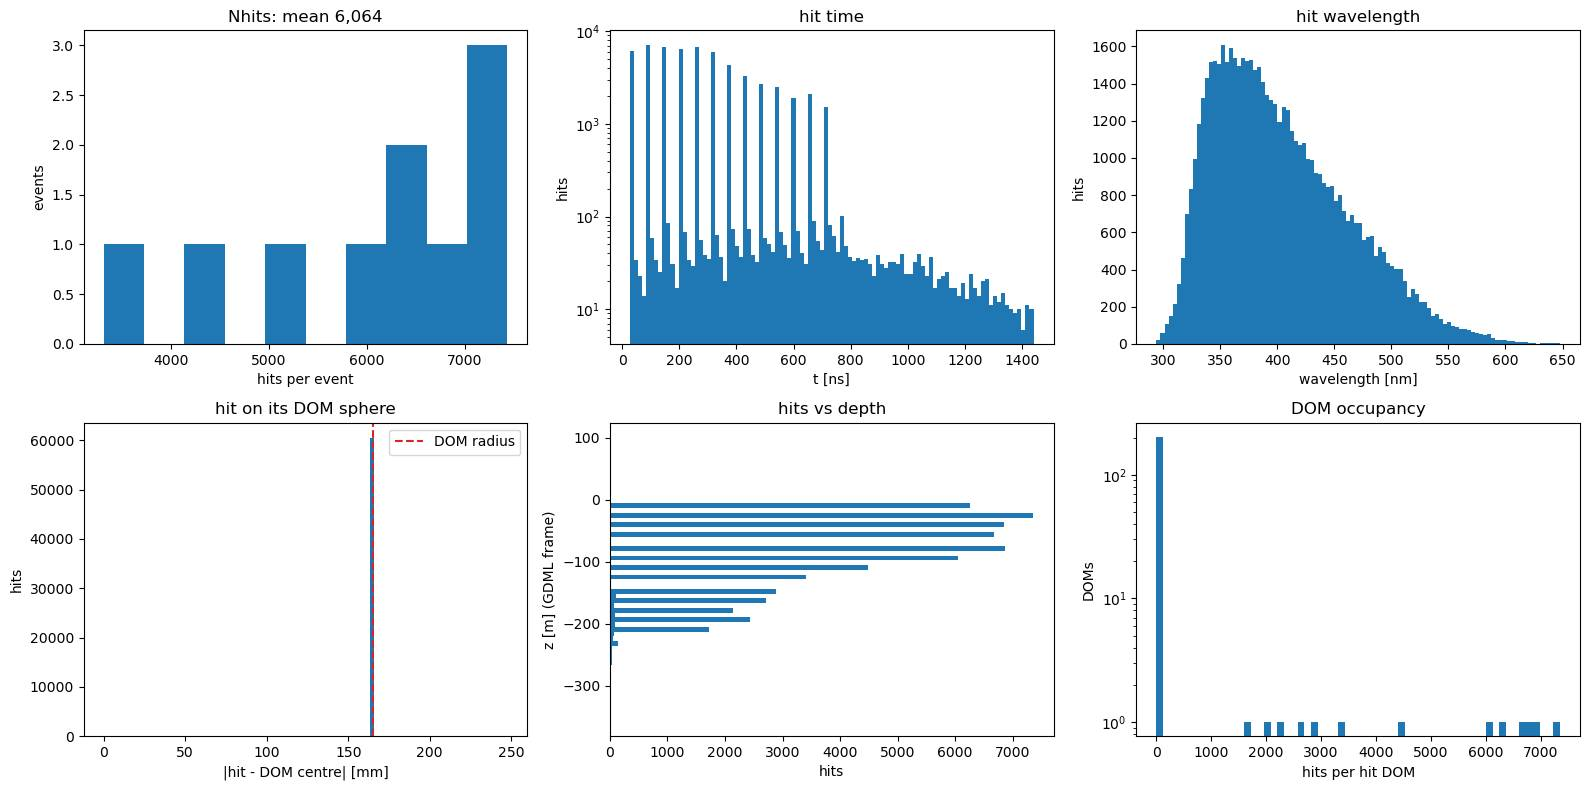

In [36]:
plot_hit_checks(hits, sensors);

In [ ]:
sensors.assign(hits=counts).nlargest(10, "hits")[["copynumber", "string", "dom", "deepcore", "x", "y", "z", "hits"]]